# Fix it before it fails: predictive maintenance

Stephen tAMBI

NASA C-MAPSS FD001: 100 turbofan engines run to failure (training) and 100 stopped before failure (test). Goal: predict remaining useful life (RUL) from 15 sensors, then compare maintenance policies. Put `train_FD001.txt`, `test_FD001.txt` and `RUL_FD001.txt` in `../data/`.

In [1]:
%run ../scripts/train_model.py ../data

{'Average engine (no model)': {'rmse': 40.1}, 'Linear regression': {'rmse': 19.0, 'mae': 14.8}, 'Random forest': {'rmse': 14.8, 'mae': 10.7}, 'Gradient boosting': {'rmse': 14.4, 'mae': 10.6}} Gradient boosting


{"trainEngines": 100, "testEngines": 100, "rows": 33727, "sensors": 15, "lifeMin": 128, "lifeMax": 362, "lifeMedian": 199} [{'th': 0, 'cycles': 20606, 'failures': 79, 'services': 21, 'wasted': 25}, {'th': 10, 'cycles': 19613, 'failures': 0, 'services': 100, 'wasted': 1018}, {'th': 20, 'cycles': 18634, 'failures': 0, 'services': 100, 'wasted': 1997}, {'th': 30, 'cycles': 17616, 'failures': 0, 'services': 100, 'wasted': 3015}, {'th': 40, 'cycles': 16471, 'failures': 0, 'services': 100, 'wasted': 4160}, {'th': 50, 'cycles': 15118, 'failures': 0, 'services': 100, 'wasted': 5513}, {'th': 60, 'cycles': 14137, 'failures': 0, 'services': 100, 'wasted': 6494}] [{'n': 100, 'cycles': 10000, 'failures': 0, 'services': 100, 'wasted': 10631}, {'n': 140, 'cycles': 13977, 'failures': 4, 'services': 96, 'wasted': 6654}, {'n': 180, 'cycles': 17391, 'failures': 29, 'services': 71, 'wasted': 3240}, {'n': 220, 'cycles': 19356, 'failures': 73, 'services': 27, 'wasted': 1275}, {'n': 260, 'cycles': 20148, 'fa

## Model accuracy on 100 unseen test engines (RMSE in cycles, RUL capped at 125)

In [2]:
import pandas as pd
pd.DataFrame(scores).T

,rmse,mae
Average engine (no model),40.1,NaN
Linear regression,19.0,14.8
Random forest,14.8,10.7
Gradient boosting,14.4,10.6


## Maintenance policies (5-fold out-of-fold predictions on the training engines)

In [3]:
cp, cf = 10_000, 100_000
rate = lambda p: (p['services'] * cp + p['failures'] * cf) / p['cycles'] * 1000
pred = pd.DataFrame(pred_pol); fix = pd.DataFrame(fix_pol)
pred['cost_per_1000_cycles'] = pred.apply(rate, axis=1); fix['cost_per_1000_cycles'] = fix.apply(rate, axis=1)
print('Best fixed schedule:'); print(fix.loc[fix.cost_per_1000_cycles.idxmin()])
print('\nPredictive, safety margin 20 cycles:'); print(pred.set_index('th').loc[20])

Best fixed schedule:
n                         125.0
cycles                  12500.0
failures                    0.0
services                  100.0
wasted                   8131.0
cost_per_1000_cycles    80000.0
Name: 5, dtype: float64

Predictive, safety margin 20 cycles:
cycles                  18634.000000
failures                    0.000000
services                  100.000000
wasted                   1997.000000
cost_per_1000_cycles    53665.342922
Name: 20, dtype: float64


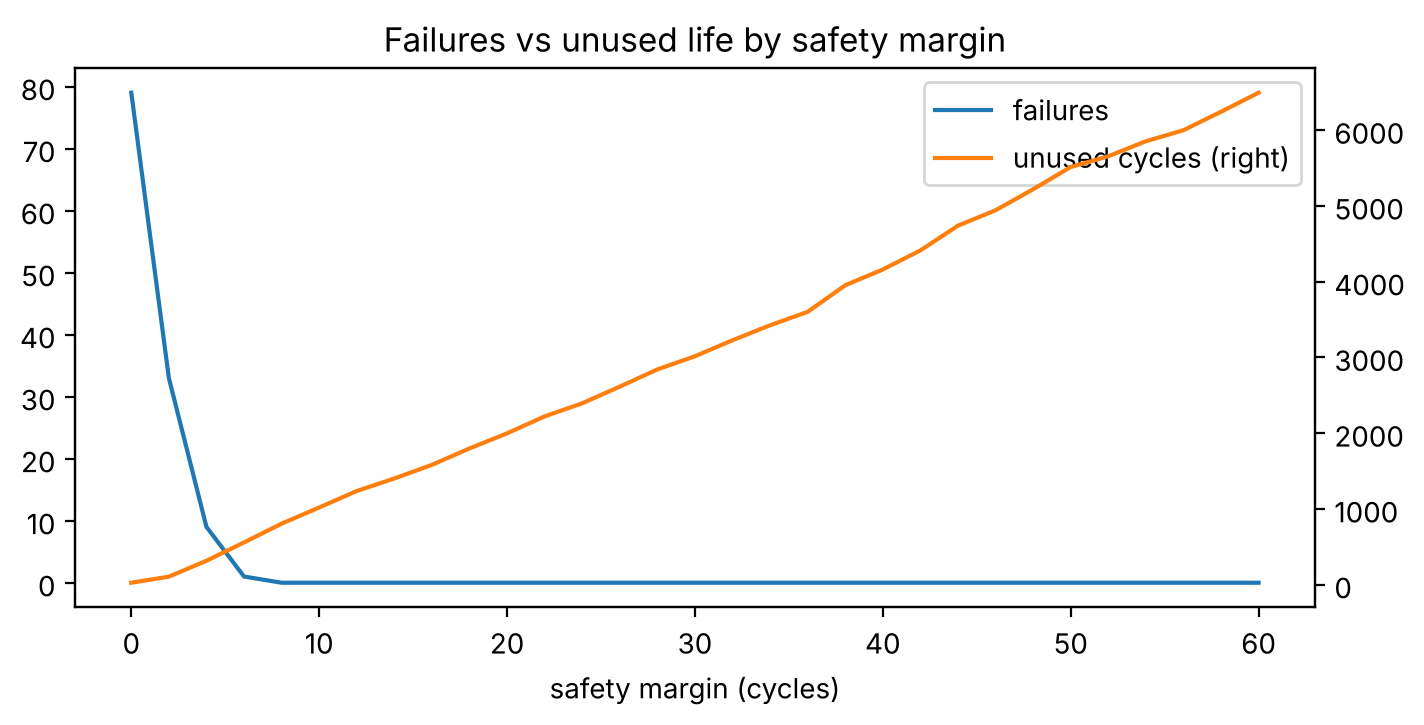

In [4]:
import matplotlib.pyplot as plt
ax = pred.plot(x='th', y='failures', label='failures', figsize=(8, 3.5))
pred.plot(x='th', y='wasted', secondary_y=True, ax=ax, label='unused cycles')
ax.set_xlabel('safety margin (cycles)'); plt.title('Failures vs unused life by safety margin'); plt.show()

## Recommendations
1. Start with a wide safety margin (20 cycles: no failures), then narrow it.
2. Rank the fleet by predicted remaining life every day.
3. Turn maintenance logs into failure labels (language models can help).
4. Show engineers which sensors drove each alert.

Interactive version: https://stambi292.github.io/predictive-maintenance/